1. Import Libraries

In [1]:
import sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

2. Display Data / Load Dataset

In [2]:
data = pd.read_csv('fraud_dataset.csv')
data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


3. Data UnderStanding

In [3]:
data.shape

(6362620, 11)

In [4]:
data.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [6]:
data.describe() 

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


4. Data Cleaning

In [7]:
data.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [8]:
data.duplicated().sum()

np.int64(0)

5. Exploratory Data Analysis (EDA)

5.1 Transaction Type

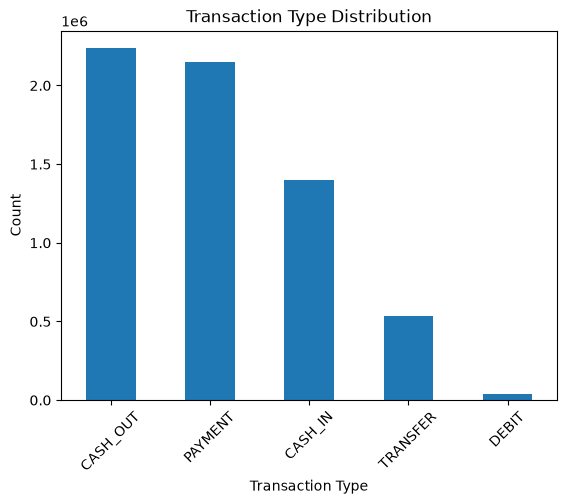

In [9]:
data['type'].value_counts().plot(kind='bar')
plt.title('Transaction Type Distribution')
plt.xlabel('Transaction Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

5.2 Fraud Distribution

In [10]:
data.groupby('type')['isFraud'].sum

fraud_by_type = data.groupby('type')['isFraud'].agg(['sum', 'count'])
fraud_by_type['fraud_percentage'] = (fraud_by_type['sum'] / fraud_by_type['count']) * 100
fraud_by_type

,sum,count,fraud_percentage
type,,,
CASH_IN,0,1399284,0.000000
CASH_OUT,4116,2237500,0.183955
DEBIT,0,41432,0.000000
PAYMENT,0,2151495,0.000000
TRANSFER,4097,532909,0.768799


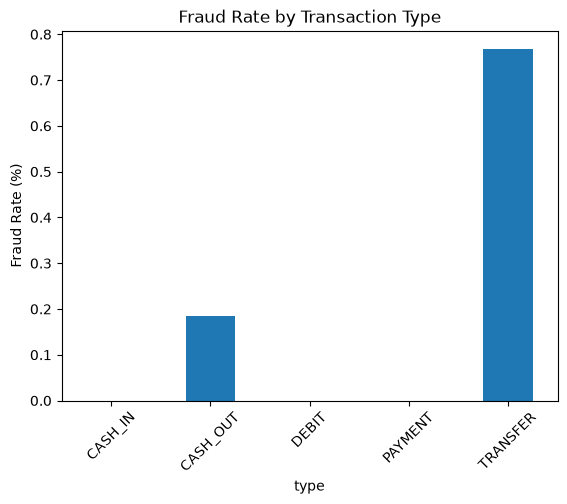

In [11]:
fraud_by_type["fraud_percentage"].plot(kind="bar")

plt.title("Fraud Rate by Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.show()

In [12]:
data["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [13]:
data["isFraud"].value_counts(normalize=True) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

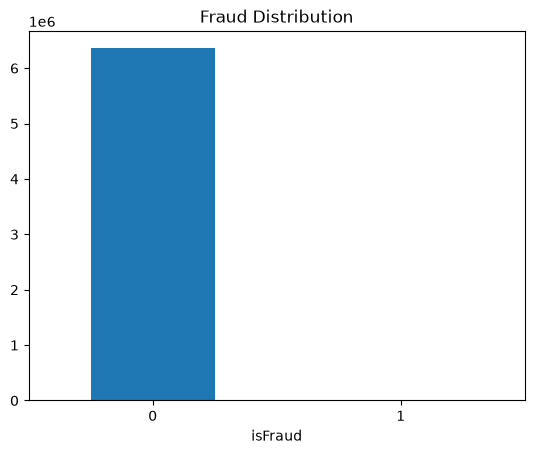

In [14]:
data['isFraud'].value_counts().plot(kind='bar')
plt.title('Fraud Distribution')
plt.xticks(rotation=0)
plt.show()

The target variable (isFraud) is highly imbalanced. Approximately 99% of transactions are legitimate, while less than 1% are fraudulent. This imbalance makes fraud detection a challenging classification problem and indicates that evaluation metrics such as Precision, Recall, and F1-score are more appropriate than Accuracy.

5.3 Transaction Amount Analysis

In [15]:
data.groupby("isFraud")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


Fraudulent transactions have a significantly higher average and median transaction amount than legitimate transactions. However, the largest transaction in the dataset belongs to a legitimate transaction, indicating that transaction amount alone is insufficient to identify fraud. Additional features such as transaction type and account balance are likely required for accurate fraud detection.

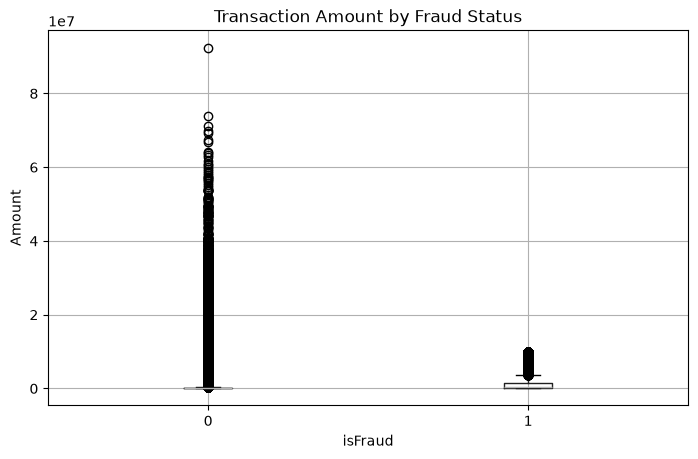

In [16]:
data.boxplot(column="amount", by="isFraud", figsize=(8,5))

plt.title("Transaction Amount by Fraud Status")
plt.suptitle("")
plt.xlabel("isFraud")
plt.ylabel("Amount")

plt.show()

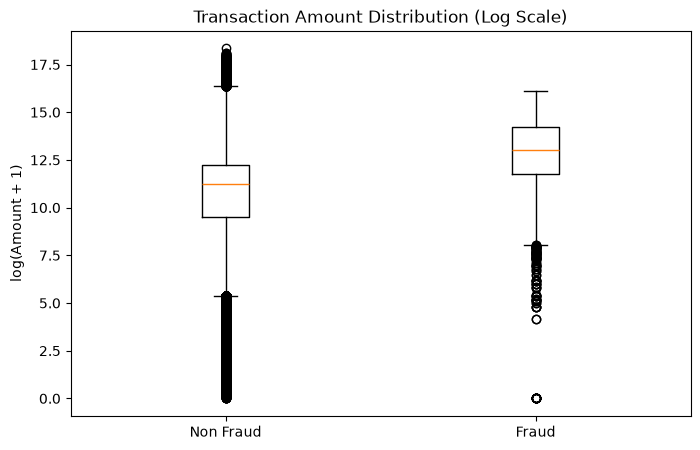

In [17]:
plt.figure(figsize=(8,5))

plt.boxplot([
    np.log1p(data[data["isFraud"] == 0]["amount"]),
    np.log1p(data[data["isFraud"] == 1]["amount"])
])

plt.xticks([1, 2], ["Non Fraud", "Fraud"])
plt.ylabel("log(Amount + 1)")
plt.title("Transaction Amount Distribution (Log Scale)")

plt.show()

The median transaction amount for fraudulent transactions is noticeably higher than that of legitimate transactions. Fraudulent transactions are generally associated with larger amounts, although both classes contain outliers. This suggests that transaction amount is an informative feature but should be combined with other variables for effective fraud detection.

In [18]:
pd.crosstab(data["type"], data["isFraud"])

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


In [19]:
pd.crosstab(
    data["type"],
    data["isFraud"],
    normalize="index"
) * 100

isFraud,0,1
type,,
CASH_IN,100.000000,0.000000
CASH_OUT,99.816045,0.183955
DEBIT,100.000000,0.000000
PAYMENT,100.000000,0.000000
TRANSFER,99.231201,0.768799


5.4 Account Balance Analysis

In [20]:
balance_cols = [
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

data.groupby("isFraud")[balance_cols].describe()

oldbalanceOrg                                                         \
                count          mean           std  min        25%        50%   
isFraud                                                                        
0           6354407.0  8.328287e+05  2.887144e+06  0.0       0.00   14069.00   
1              8213.0  1.649668e+06  3.547719e+06  0.0  125822.44  438983.45   

                                 newbalanceOrig                 ...  \
                75%          max          count           mean  ...   
isFraud                                                         ...   
0         106969.50  43818855.30      6354407.0  855970.228109  ...   
1        1517771.48  59585040.37         8213.0  192392.631836  ...   

        oldbalanceDest               newbalanceDest                \
                   75%           max          count          mean   
isFraud                                                             
0            944144.58  3.560159e+08      6354407.0  1.224926e+06   
1            147828.66  2.362305e+08         8213.0  1.279708e+06   

                                                                       
                  std  min  25%        50%          75%           max  
isFraud                                                                
0        3.673816e+06  0.0  0.0  214881.70  1111975.345  3.561793e+08  
1        3.908817e+06  0.0  0.0    4676.42  1058725.220  2.367265e+08  

[2 rows x 32 columns]

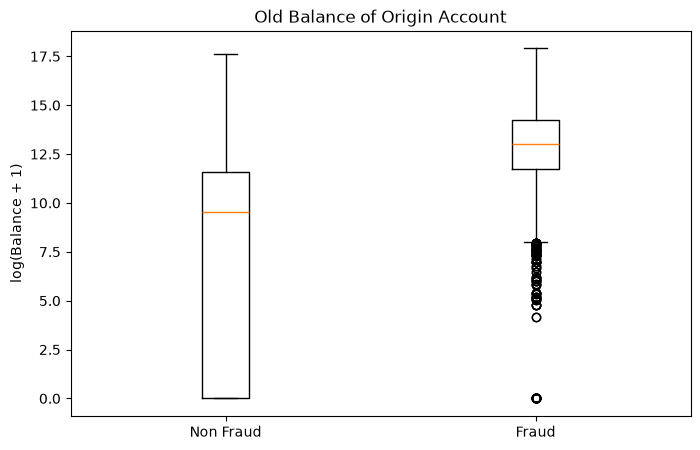

In [21]:
plt.figure(figsize=(8,5))

plt.boxplot([
    np.log1p(data[data["isFraud"] == 0]["oldbalanceOrg"]),
    np.log1p(data[data["isFraud"] == 1]["oldbalanceOrg"])
])

plt.xticks([1,2], ["Non Fraud", "Fraud"])
plt.ylabel("log(Balance + 1)")
plt.title("Old Balance of Origin Account")

plt.show()

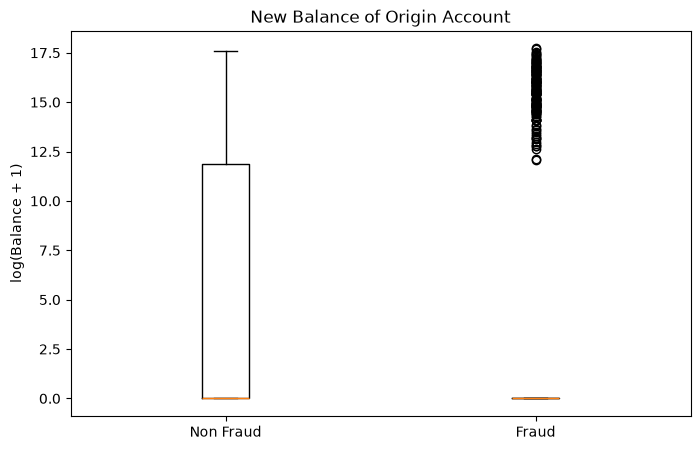

In [22]:
plt.figure(figsize=(8,5))

plt.boxplot([
    np.log1p(data[data["isFraud"] == 0]["newbalanceOrig"]),
    np.log1p(data[data["isFraud"] == 1]["newbalanceOrig"])
])

plt.xticks([1,2], ["Non Fraud", "Fraud"])
plt.ylabel("log(Balance + 1)")
plt.title("New Balance of Origin Account")

plt.show()

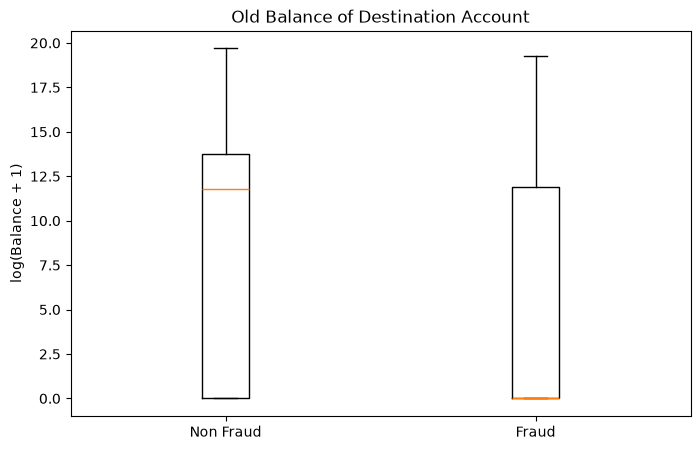

In [23]:
plt.figure(figsize=(8,5))

plt.boxplot([
    np.log1p(data[data["isFraud"] == 0]["oldbalanceDest"]),
    np.log1p(data[data["isFraud"] == 1]["oldbalanceDest"])
])

plt.xticks([1,2], ["Non Fraud", "Fraud"])
plt.ylabel("log(Balance + 1)")
plt.title("Old Balance of Destination Account")

plt.show()

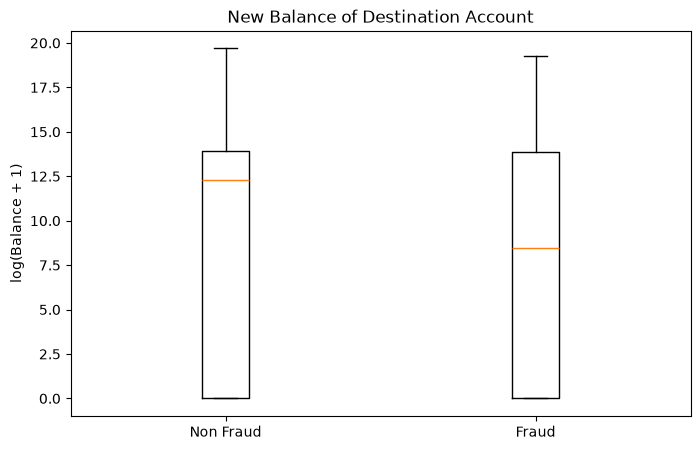

In [24]:
plt.figure(figsize=(8,5))

plt.boxplot([
    np.log1p(data[data["isFraud"] == 0]["newbalanceDest"]),
    np.log1p(data[data["isFraud"] == 1]["newbalanceDest"])
])

plt.xticks([1,2], ["Non Fraud", "Fraud"])
plt.ylabel("log(Balance + 1)")
plt.title("New Balance of Destination Account")

plt.show()

5.5 Correlation Analysis

In [25]:
corr = data.corr(numeric_only=True)
corr["isFraud"].sort_values(ascending=False)

isFraud           1.000000
amount            0.076688
isFlaggedFraud    0.044109
step              0.031578
oldbalanceOrg     0.010154
newbalanceDest    0.000535
oldbalanceDest   -0.005885
newbalanceOrig   -0.008148
Name: isFraud, dtype: float64

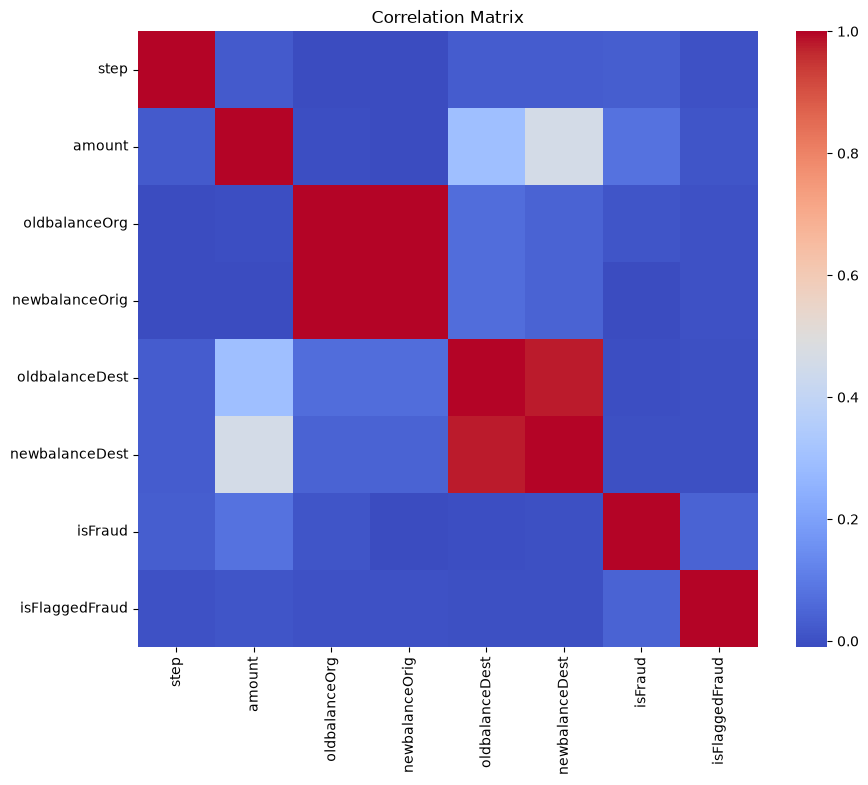

In [26]:
plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Matrix")
plt.show()

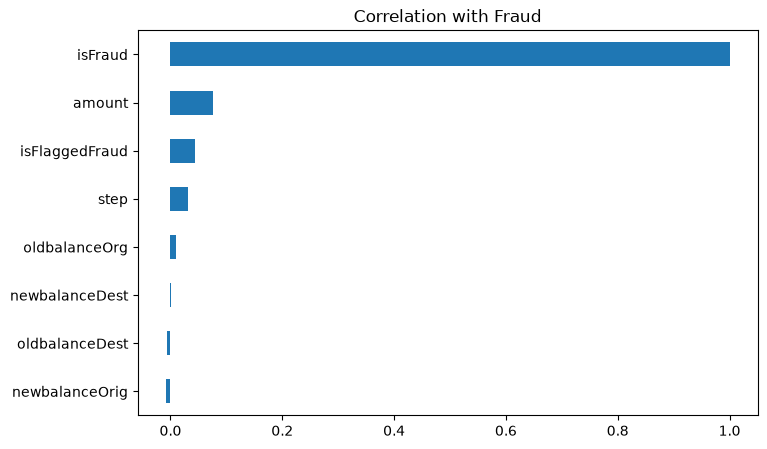

In [27]:
corr["isFraud"].sort_values().plot(kind="barh", figsize=(8,5))

plt.title("Correlation with Fraud")
plt.show()

Based on the Correlation with Fraud analysis, no numerical feature shows a strong linear correlation with the target variable (isFraud). Among all features, amount has the highest positive correlation with fraud, but the correlation is still relatively weak. This indicates that fraudulent transactions cannot be identified using a single feature alone. Therefore, machine learning models should learn from the combination of multiple features to accurately detect fraudulent transactions.

6. Data Preprocessing

In [28]:
data.drop(columns=["nameOrig", "nameDest", "isFlaggedFraud"], inplace=True)

In [29]:
data = pd.get_dummies(data, columns=["type"], drop_first=True)

In [30]:
X = data.drop( "isFraud", axis = 1)
Y = data["isFraud"]

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0, stratify=Y)

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

7. Logistic Regression

In [33]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression( random_state = 42, class_weight = "balanced" , max_iter = 1000)
lr.fit(X_train_scaled, Y_train)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [34]:
y_pred = lr.predict(X_test_scaled)

In [35]:
y_prob = lr.predict_proba(X_test_scaled)[:, 1]

In [36]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print(classification_report(Y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1270881
           1       0.02      0.94      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.95      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524



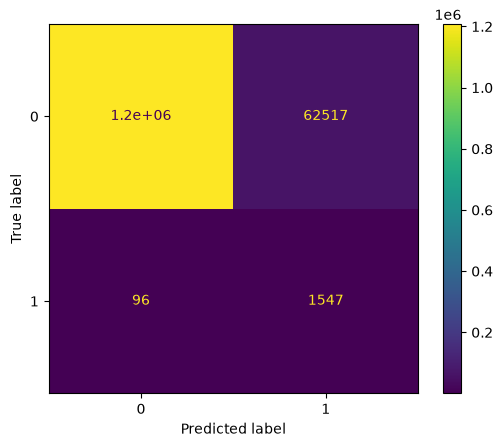

In [37]:
ConfusionMatrixDisplay.from_predictions(Y_test, y_pred)

plt.show()

In [38]:
from sklearn.metrics import roc_auc_score

roc_auc_score(Y_test, y_prob)

0.9889131146108395

In [39]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []
results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(Y_test, y_pred),
    "Precision": precision_score(Y_test, y_pred),
    "Recall": recall_score(Y_test, y_pred),
    "F1": f1_score(Y_test, y_pred),
    "ROC": roc_auc_score(Y_test, y_prob)
})

results

[{'Model': 'Logistic Regression',
  'Accuracy': 0.9507962128808572,
  'Precision': 0.024147727272727272,
  'Recall': 0.9415702982349361,
  'F1': 0.04708782930281401,
  'ROC': 0.9889131146108395}]

The Logistic Regression model achieved a Recall of 94%, meaning that it successfully detected most fraudulent transactions. However, the Precision was only 2%, indicating a large number of false positive predictions. The confusion matrix shows that while only 96 fraudulent transactions were missed, more than 62,000 legitimate transactions were incorrectly classified as fraud. Although the ROC-AUC score reached 0.989, the model still struggles to achieve a good balance between Precision and Recall. Therefore, Logistic Regression serves as a baseline model, while more advanced tree-based models such as Random Forest are expected to provide better overall performance.

8. Random Forest

In [40]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf.fit(X_train, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [41]:
y_pred_rf = rf.predict(X_test)

y_prob_rf = rf.predict_proba(X_test)[:,1]

In [42]:
print(classification_report(Y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.94      0.83      0.88      1643

    accuracy                           1.00   1272524
   macro avg       0.97      0.92      0.94   1272524
weighted avg       1.00      1.00      1.00   1272524



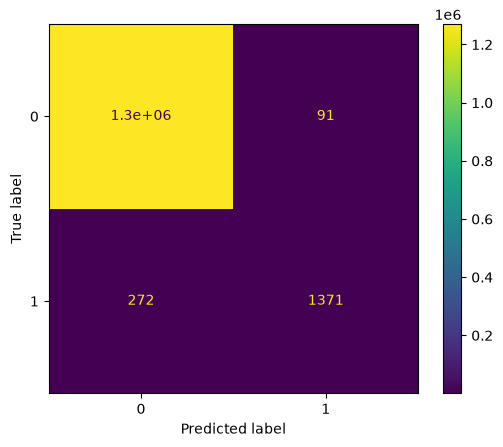

In [43]:
ConfusionMatrixDisplay.from_predictions(
    Y_test,
    y_pred_rf
)

plt.show()

In [44]:
from sklearn.metrics import roc_auc_score

roc_auc_score(Y_test, y_prob_rf)

0.9980370272210557

In [45]:
results.append({
    "Model":"Random Forest",
    "Accuracy":accuracy_score(Y_test,y_pred_rf),
    "Precision":precision_score(Y_test,y_pred_rf),
    "Recall":recall_score(Y_test,y_pred_rf),
    "F1":f1_score(Y_test,y_pred_rf),
    "ROC":roc_auc_score(Y_test,y_prob_rf)
})

import pandas as pd

pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1,ROC
0,Logistic Regression,0.950796,0.024148,0.941570,0.047088,0.988913
1,Random Forest,0.999715,0.937756,0.834449,0.883092,0.998037


Random Forest significantly outperformed Logistic Regression on all key evaluation metrics. While Logistic Regression achieved a higher recall (94.16%), it suffered from extremely low precision (2.41%), resulting in a large number of false positive predictions. In contrast, Random Forest achieved a precision of 93.78% while maintaining a strong recall of 83.44%, leading to a much higher F1-score (88.31%). Furthermore, Random Forest obtained the highest ROC-AUC score (0.9980), indicating excellent discrimination between fraudulent and legitimate transactions. Therefore, Random Forest was selected as the best-performing model for this fraud detection task.

9. Feature Importance

In [46]:
importance = pd.DataFrame({
    "Feature":X_train.columns,
    "Importance":rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(15)

,Feature,Importance
2,oldbalanceOrg,0.297180
3,newbalanceOrig,0.184538
1,amount,0.158092
9,type_TRANSFER,0.089988
0,step,0.061505
5,newbalanceDest,0.058041
8,type_PAYMENT,0.056929
6,type_CASH_OUT,0.050376
4,oldbalanceDest,0.043136
7,type_DEBIT,0.000215


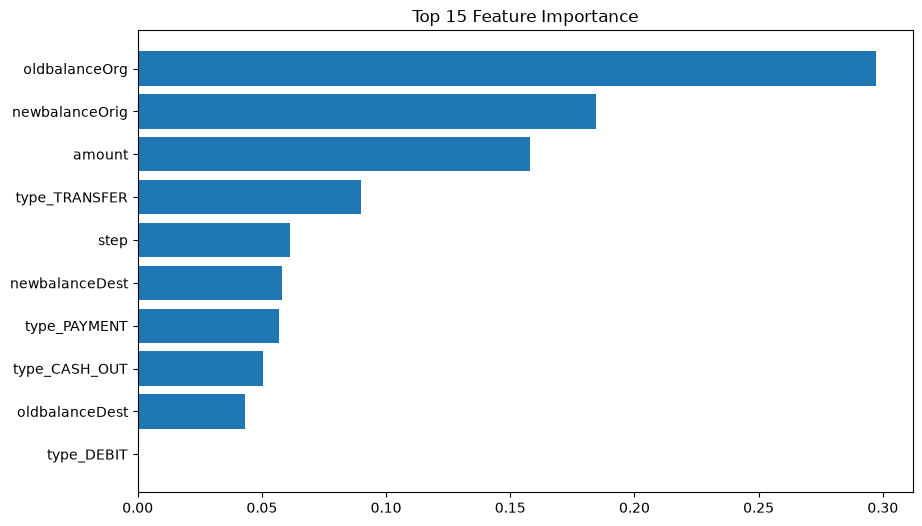

In [47]:
plt.figure(figsize=(10,6))

plt.barh(
    importance["Feature"][:15],
    importance["Importance"][:15]
)

plt.gca().invert_yaxis()

plt.title("Top 15 Feature Importance")

plt.show()

Feature importance analysis shows that oldbalanceOrg, newbalanceOrig, and amount are the three most influential features in detecting fraudulent transactions. Transaction type, particularly TRANSFER, also contributes significantly to the prediction. These findings are consistent with the exploratory data analysis, which indicated that fraudulent transactions generally involve larger transaction amounts and specific transaction types. Additionally, the importance of the step feature suggests that the timing of transactions provides useful information when combined with other variables.

10. Hyperparameter Tuning

In [49]:
sample_data = data.sample(n=100000, random_state=42)

In [50]:
X_sample = sample_data.drop("isFraud", axis=1)
y_sample = sample_data["isFraud"]

In [54]:
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_sample,
    y_sample,
    test_size=0.2,
    random_state=42,
    stratify=y_sample
)

In [55]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [50, 100],
    "max_depth": [10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=4,         
    cv=2,             
    scoring="f1",
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_s,y_train_s)

Fitting 2 folds for each of 4 candidates, totalling 8 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 20], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [50, 100]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",4
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",2
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index

In [56]:
random_search.best_params_

{'n_estimators': 50,
 'min_samples_split': 5,
 'min_samples_leaf': 2,
 'max_depth': 20}

In [62]:
best_rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=20,
    min_samples_leaf=2,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train, Y_train)

y_pred = best_rf.predict(X_test)

In [64]:
print(classification_report(Y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.98      0.75      0.85      1643

    accuracy                           1.00   1272524
   macro avg       0.99      0.88      0.93   1272524
weighted avg       1.00      1.00      1.00   1272524



In [65]:
from sklearn.metrics import roc_auc_score

y_prob_tuned = best_rf.predict_proba(X_test)[:,1]

roc = roc_auc_score(Y_test, y_prob_tuned)

print("ROC-AUC :", roc)

ROC-AUC : 0.9992166975701979


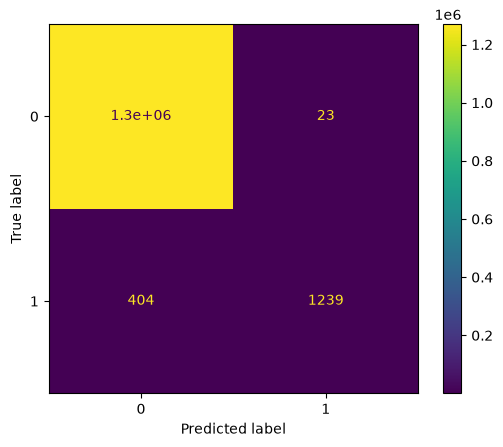

In [66]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    Y_test,
    y_pred
)

plt.show()

Final Conclusion

This study developed a machine learning model to detect fraudulent financial transactions using a dataset containing 6,362,620 transactions. The dataset is highly imbalanced, with 99.87% legitimate transactions and only 0.13% fraudulent transactions, making fraud detection a challenging classification problem.

During the Exploratory Data Analysis (EDA), it was found that fraudulent transactions predominantly occurred in the TRANSFER and CASH_OUT transaction types. In addition, fraudulent transactions generally involved significantly larger transaction amounts than legitimate ones. Feature importance analysis using the Random Forest model revealed that oldbalanceOrg, newbalanceOrig, and amount were the most influential features for fraud detection.

Two machine learning models, Logistic Regression and Random Forest, were trained and evaluated. Logistic Regression achieved a high recall of 94.16%, indicating that it successfully detected most fraudulent transactions. However, its precision was only 2.41%, resulting in a large number of false positive predictions. In contrast, the Random Forest model achieved a much more balanced performance, with an accuracy of 99.97%, precision of 93.78%, recall of 83.44%, F1-score of 88.31%, and ROC-AUC of 99.80%.

Hyperparameter tuning was then performed on the Random Forest model using RandomizedSearchCV to optimize its performance. The tuned model increased the precision from 93.78% to 98.00%, reducing the number of false positive predictions. However, the recall decreased from 83.44% to 75.00%, indicating that more fraudulent transactions were missed. Consequently, the F1-score also decreased from 88.31% to 85.00%. Since fraud detection prioritizes identifying as many fraudulent transactions as possible, the untuned Random Forest model was selected as the final model because it provided a better balance between precision and recall.

Overall, the results demonstrate that the Random Forest algorithm outperformed Logistic Regression for this fraud detection task. The model achieved excellent classification performance while maintaining a strong balance between identifying fraudulent transactions and minimizing incorrect fraud predictions. Therefore, the Random Forest model without hyperparameter tuning was selected as the most suitable model for this fraud detection system due to its superior overall performance and better capability to detect fraudulent transactions.

In [67]:
import joblib

joblib.dump(rf, "fraud_detection_model.pkl")

print("Model saved as fraud_detection_model.pkl")

Model saved as fraud_detection_model.pkl
